### **Exploratory Data Analysis**

**<u>Dataset I</u>**

Description: Images of maize plants, labelled with "watered" or "drought"

Source: https://zenodo.org/records/10991581

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import math
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.preprocessing import MinMaxScaler

sns.set_theme(style='darkgrid')

plt.rcParams.update({
    'font.family': 'monospace',
    'axes.labelsize': 10,
    'axes.titlesize': 11,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8
})


In [2]:
"""---------------------------------
Analysis for Dataset I
------------------------------------"""

DATA_ROOT_1 = Path("maize_watered_drought_sorted")

records = []; count=0
for split in DATA_ROOT_1.iterdir():
    for category in split.iterdir():
        count = len([file for file in category.iterdir()])

        records.append({
            'Split': split.name,
            'Category': category.name,
            'Count': count
        })

DATA_1 = pd.DataFrame(records)
DATA_1 = DATA_1.sort_values(by="Count", ascending=False)
DATA_1

,Split,Category,Count
2,train,Drought_Trial001_2,1864
3,train,Watered_Trial001_1,1814
0,test,Drought_Trial001_2,400
4,validation,Drought_Trial001_2,399
1,test,Watered_Trial001_1,389
5,validation,Watered_Trial001_1,389


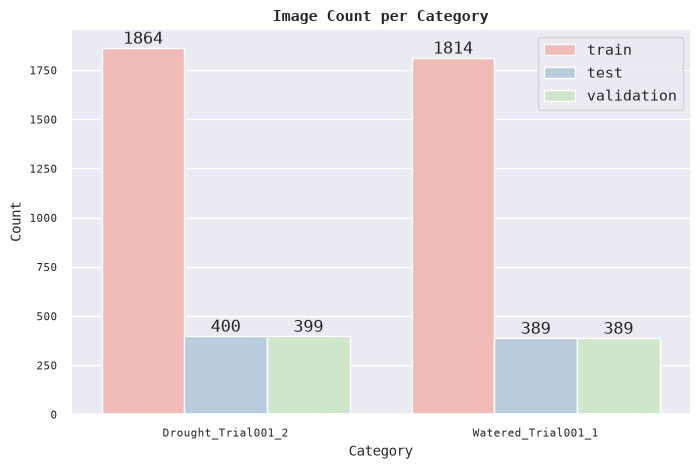

In [3]:
"""---------------------------------
Analysis for Dataset I [Distribution]
------------------------------------"""
def category_distribution(df):
    fig, ax = plt.subplots(figsize=(8,5))

    sns.barplot(
        data=df,
        x="Category",
        y="Count",
        ax=ax,
        hue="Split",
        palette='Pastel1'
    )

    ax.set_title('Image Count per Category', fontsize=11, fontweight='bold')
    ax.legend()

    for c in ax.containers:
        ax.bar_label(c)
    plt.show()

category_distribution(DATA_1)



In [4]:
"""---------------------------------
Analysis for Dataset II | Stats for all Columns
------------------------------------"""

DATA_2 = pd.read_csv('Edge_IoT_Predictive_Irrigation_Dataset.csv')
DATA_2["Timestamp"] = pd.to_datetime(DATA_2["Timestamp"])
print(DATA_2.describe)

DATA_2.describe().round(2)

<bound method NDFrame.describe of               Timestamp  Day   Time  Temperature_C  Humidity_pct  \
0   2026-04-13 17:30:00   13  17:30           32.1            66   
1   2026-04-13 17:00:00   13  17:00           32.8            66   
2   2026-04-13 16:30:00   13  16:30           32.9            65   
3   2026-04-13 16:00:00   13  16:00           33.1            65   
4   2026-04-13 15:30:00   13  15:30           33.5            64   
..                  ...  ...    ...            ...           ...   
955 2026-04-16 06:30:00   16   6:30           27.1            77   
956 2026-04-17 18:00:00   17  18:00           32.1            70   
957 2026-04-17 18:30:00   17  18:30           31.6            71   
958 2026-04-19 18:00:00   19  18:00           30.9            68   
959 2026-04-19 18:30:00   19  18:30           31.2            70   

     Soil_Moisture_pct  Light_Intensity  Pump_Status  
0                 46.6               69            0  
1                 46.9              249

C:\Users\ptong\AppData\Local\Temp\ipykernel_28992\3986472832.py:6: UserWarning: Parsing dates in %d/%m/%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  DATA_2["Timestamp"] = pd.to_datetime(DATA_2["Timestamp"])


,Timestamp,Day,Temperature_C,Humidity_pct,Soil_Moisture_pct,Light_Intensity,Pump_Status
count,960,960.00,960.00,960.00,960.00,960.00,960.00
mean,2026-04-10 23:45:00,10.50,29.16,74.48,65.77,287.39,0.03
min,2026-04-01 00:00:00,1.00,25.00,61.00,46.60,0.00,0.00
25%,2026-04-05 23:52:30,5.75,25.50,66.00,59.60,0.00,0.00
50%,2026-04-10 23:45:00,10.50,29.00,75.00,63.60,25.00,0.00
75%,2026-04-15 23:37:30,15.25,32.52,83.00,68.32,640.25,0.00
max,2026-04-20 23:30:00,20.00,35.00,88.00,85.00,949.00,1.00
std,NaN,5.77,3.39,8.56,9.15,347.98,0.17


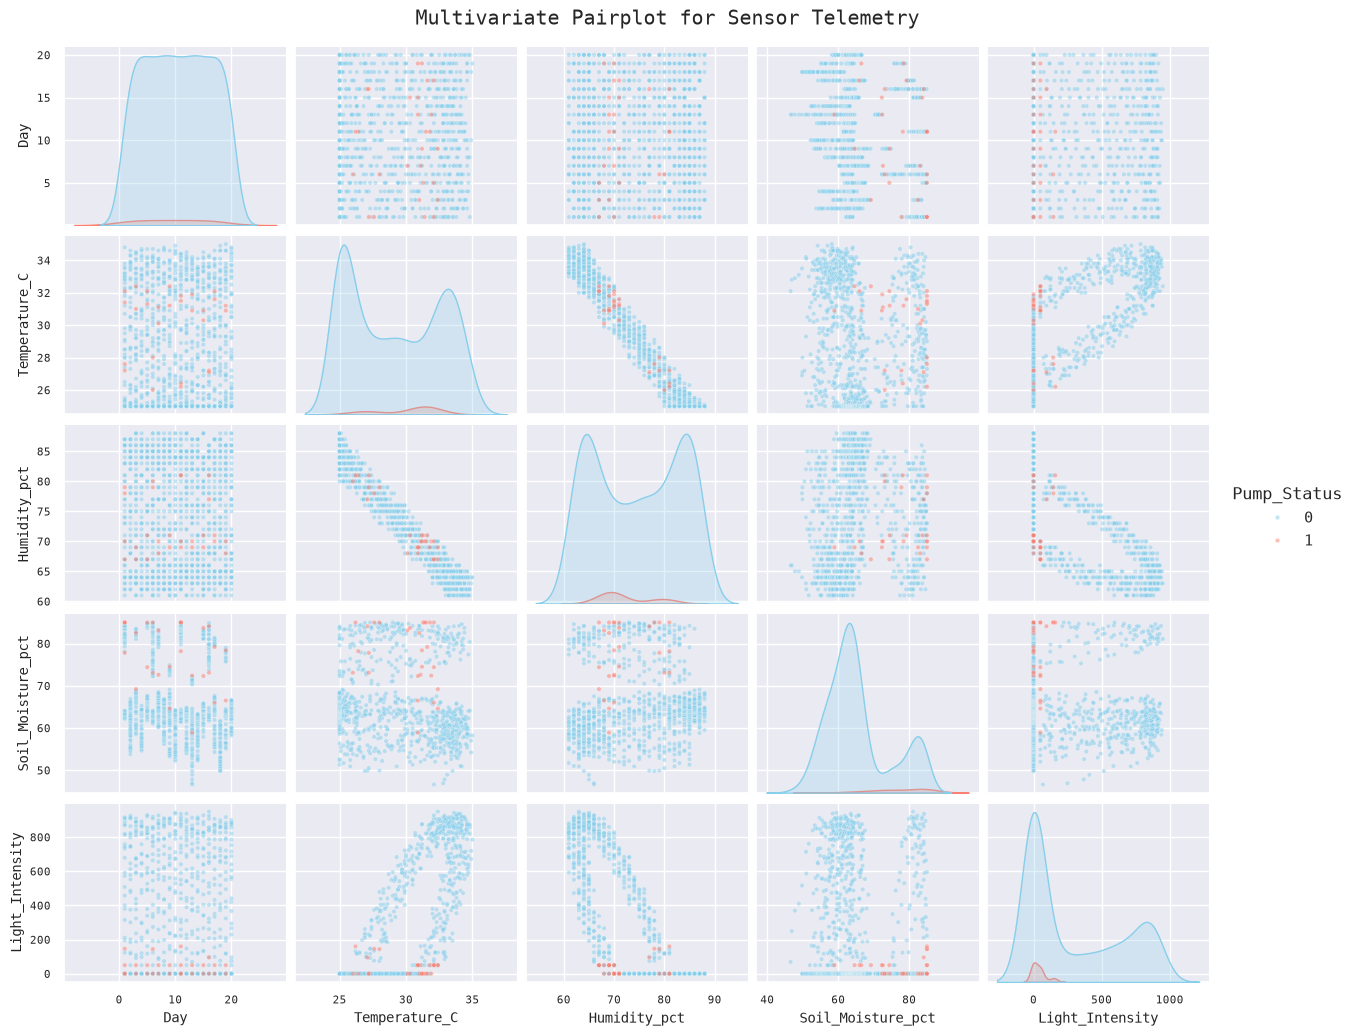

In [5]:
"""---------------------------------
Analysis for Dataset II | Multivariate Pairplot
------------------------------------"""
# DATA_2 = DATA_2.drop(columns=['Day'])
DATA_2['Pump_Status'] = DATA_2['Pump_Status'].astype(str)

ax2 = sns.pairplot(
    data = DATA_2,
    diag_kind = 'kde',
    # corner = True,
    hue = "Pump_Status",
    palette=['skyblue','salmon'],
    plot_kws = {'alpha': 0.5, 's': 10}
)
ax2.figure.subplots_adjust(top=0.8)
ax2.figure.suptitle('Multivariate Pairplot for Sensor Telemetry', y=0.83)
plt.show()


6


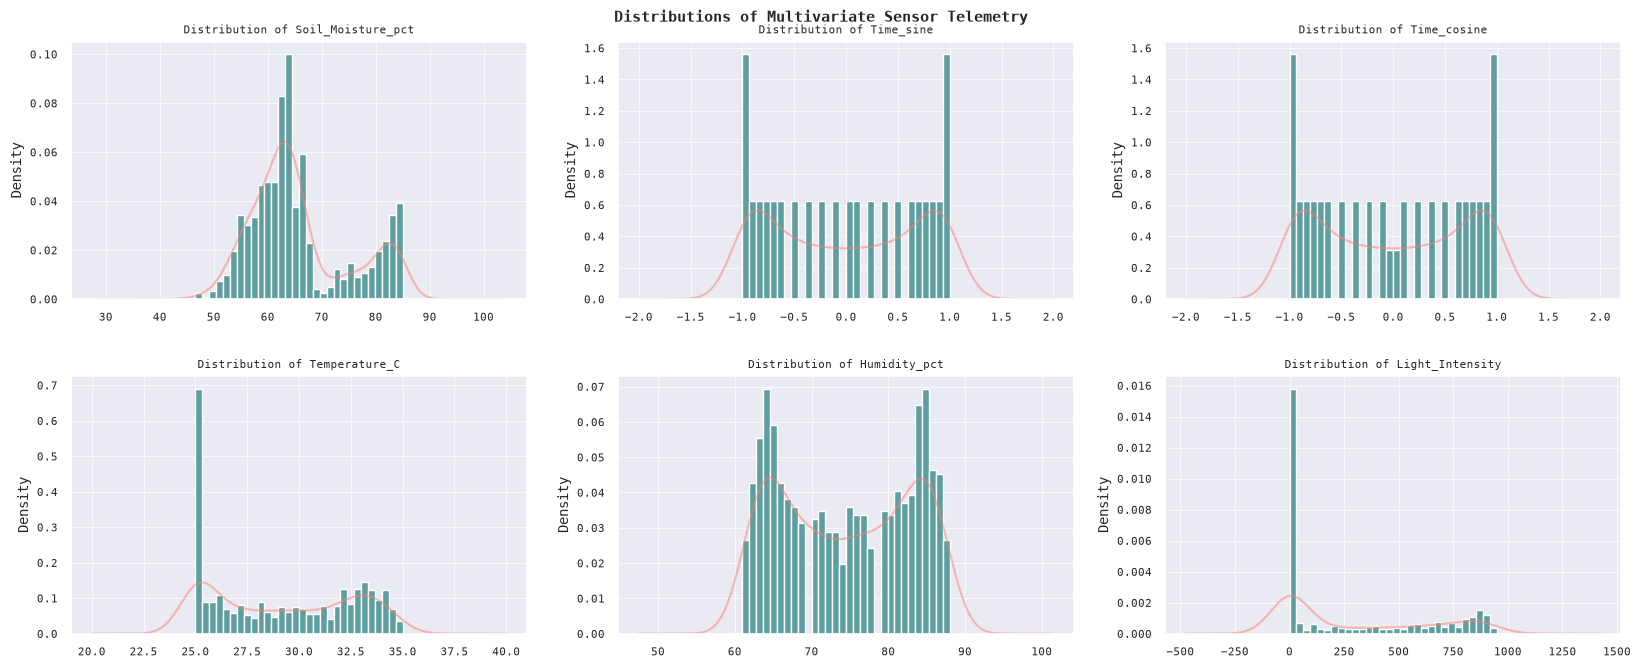

In [6]:
"""---------------------------------
Analysis for Dataset II | Distributions
------------------------------------"""

# Transformation for time column
DATA_2['Time'] = pd.to_datetime(DATA_2['Time'], format='%H:%M')
DATA_2['Hour'] = DATA_2['Time'].dt.hour	+ DATA_2['Time'].dt.minute/60.0
DATA_2['Time_sine'] = np.sin(2 * np.pi * DATA_2["Hour"]/24.0)
DATA_2['Time_cosine'] = np.cos(2 * np.pi * DATA_2["Hour"]/24.0)

# numerical_cols = DATA_2.select_dtypes(include=['number']).columns
numerical_cols = ['Soil_Moisture_pct','Time_sine','Time_cosine', 'Temperature_C', 'Humidity_pct', 'Light_Intensity']
print(len(numerical_cols))
# Generate the plot
fig3, ax3 = plt.subplots(nrows=2, ncols=math.ceil(len(numerical_cols) / 2), figsize=(20,8))
ax3 = ax3.flatten()

for i, col in enumerate(numerical_cols):
    ax_current = ax3[i]

    DATA_2[col].plot(kind='hist', bins=30, color='cadetblue', ax=ax_current, density=True)
    DATA_2[col].plot(kind='kde', color='salmon', ax=ax_current, alpha=0.5)

    ax_current.grid(True, linewidth=0.5)
    ax_current.set_title(f"Distribution of {col}", fontsize=8)
    
fig3.subplots_adjust(top=0.94, bottom=0.2, hspace=0.3)
fig3.suptitle("Distributions of Multivariate Sensor Telemetry", fontweight='bold', fontsize=11)
plt.show()

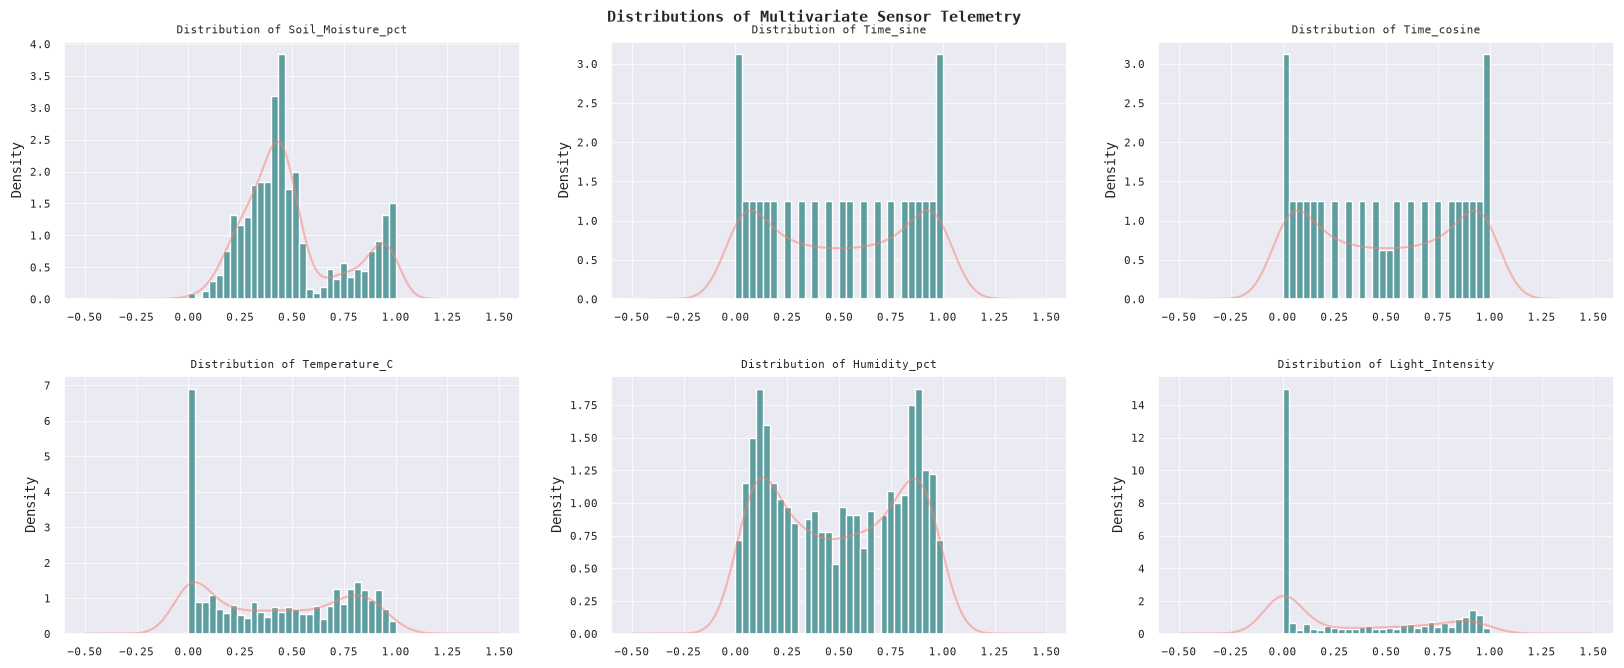

In [7]:
"""---------------------------------
Analysis for Dataset II | Scaling -> Distributions
------------------------------------"""

scaler = MinMaxScaler(feature_range=(0, 1))
FEATURES_INPUT = ['Soil_Moisture_pct','Time_sine','Time_cosine', 'Temperature_C', 'Humidity_pct', 'Light_Intensity']

SCALED_VALS = scaler.fit_transform(DATA_2[FEATURES_INPUT].values)

SCALED_DF = pd.DataFrame(SCALED_VALS, columns=FEATURES_INPUT)

fig4, ax4 = plt.subplots(nrows=2, ncols=math.ceil(len(FEATURES_INPUT) / 2), figsize=(20,8))
ax4 = ax4.flatten()

for i, col in enumerate(FEATURES_INPUT):
    ax_current = ax4[i]

    SCALED_DF[col].plot(kind='hist', bins=30, color='cadetblue', ax=ax_current, density=True)
    SCALED_DF[col].plot(kind='kde', color='salmon', ax=ax_current, alpha=0.5)

    ax_current.grid(True, linewidth=0.5)
    ax_current.set_title(f"Distribution of {col}", fontsize=8)
    
fig4.subplots_adjust(top=0.94, bottom=0.2, hspace=0.3)
fig4.suptitle("Distributions of Multivariate Sensor Telemetry", fontweight='bold', fontsize=11)

plt.show()